In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
shipment = pd.read_excel("C:/Users/kcluv/OneDrive/Documents/Job Search/shipments_KC_Edits.xlsx")
shipment.head()

,shipment_id,carrier_name,service_level,origin_country,destination_country,origin_city,destination_city,lane_code,customs_required,weight_kg,...,Formated_actual_delivery_timestamp,last_event_timestamp,current_status,Delivered Status (Early or Late),Difference,exception_code,exception_description,num_status_changes,handoff_count,target_exception
0,SHP-2026003319,GeoCargo,EXPRESS,US,US,Houston,Houston,US-US-EXP,False,3.47,...,2025-12-17 00:46:12,2025-12-16T19:46:12-05:00,DELIVERED,LATE,0 days 02:34:18,NaN,NaN,1,1,False
1,SHP-2026002468,Expeditors,STANDARD,US,GB,Seattle,Glasgow,US-GB-STA,True,96.43,...,2026-01-14 23:48:24,2026-01-14T18:48:24-05:00,DELIVERED,LATE,0 days 11:05:56,NaN,NaN,2,5,False
2,SHP-2026006498,SwiftPort,ECON,CN,US,Beijing,Seattle,CN-US-ECO,True,10.61,...,2026-01-20 11:23:54,2026-01-20T19:23:54+08:00,DELIVERED,EARLY,0 days 06:19:39,NaN,NaN,3,2,False
3,SHP-2026006143,SwiftPort,PRIORITY,US,DE,Houston,Cologne,NaN,True,2.57,...,2026-01-16 00:00:00,2026-01-15T19:00:00-05:00,DELIVERED,LATE,0 days 09:12:17,NaN,NaN,2,4,False
4,SHP-2026004497,DHL Express,PRIORITY,DE,FR,LEIPZIG,Lille,DE-FR-PRI,False,41.04,...,2026-02-09 09:32:35,2026-02-09T10:32:35+01:00,DELIVERED,EARLY,0 days 00:59:51,NaN,NaN,2,4,False


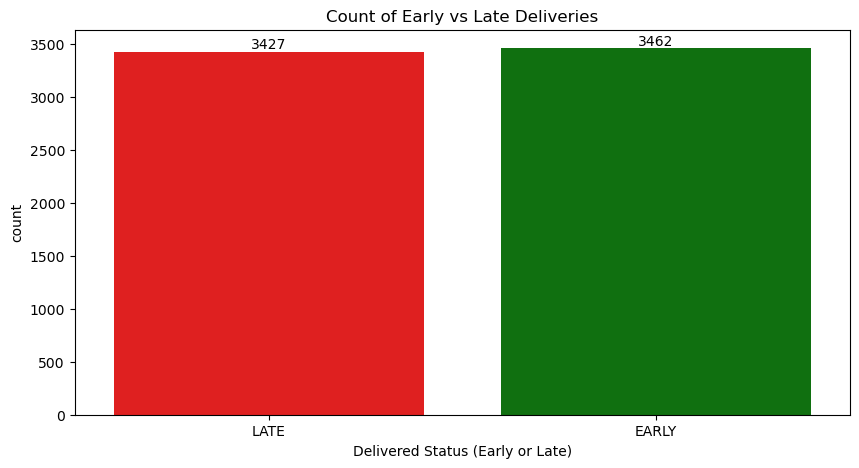

In [43]:
plt.figure(figsize=(10, 5))
ax=sns.countplot(
    data=shipment, 
    x='Delivered Status (Early or Late)', 
    hue='Delivered Status (Early or Late)', 
    palette={'LATE': 'red', 'EARLY': 'green'},
    legend=False
)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Count of Early vs Late Deliveries')
plt.show()

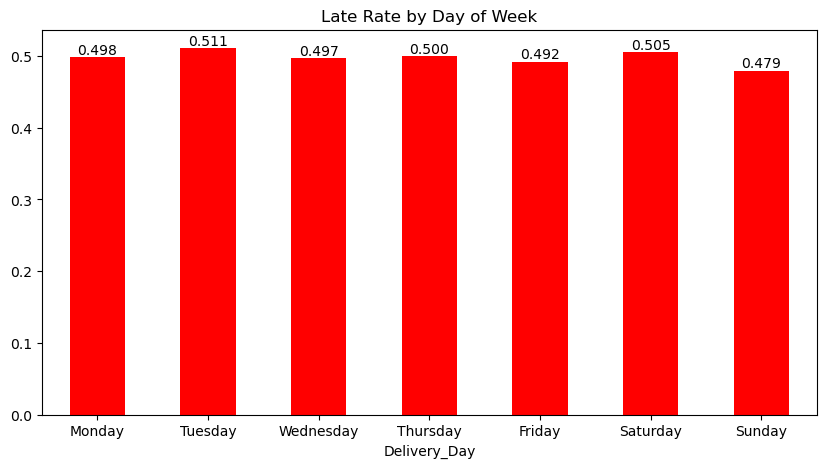

In [9]:
shipment['Delivery_Day'] = pd.to_datetime(shipment['Formated_actual_delivery_timestamp']).dt.day_name()

late_by_day = shipment.groupby('Delivery_Day')['Delivered Status (Early or Late)'] \
    .apply(lambda x: (x == 'LATE').mean())

late_by_day = late_by_day.reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])

plt.figure(figsize=(10, 5))
ax=late_by_day.plot(kind='bar', color='red', title='Late Rate by Day of Week')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f')
plt.xticks(rotation=0)
plt.show()


In [3]:
# Conclusion - recommend pushing estimated timestamp out by this time...
late_only = shipment[shipment['Delivered Status (Early or Late)'] == 'LATE']
recommendation = late_only['Difference'].quantile(0.9) 
print(f"To fix 90% of late deliveries, push estimates out by: {recommendation}")

# Use this one instead - ALL shipments
total_recommendation = shipment['Difference'].quantile(0.9)
print(f"To ensure 90% of ALL shipments are on time, push estimates out by: {total_recommendation}")


To fix 90% of late deliveries, push estimates out by: 0 days 18:39:11.400000
To ensure 90% of ALL shipments are on time, push estimates out by: 0 days 18:17:04


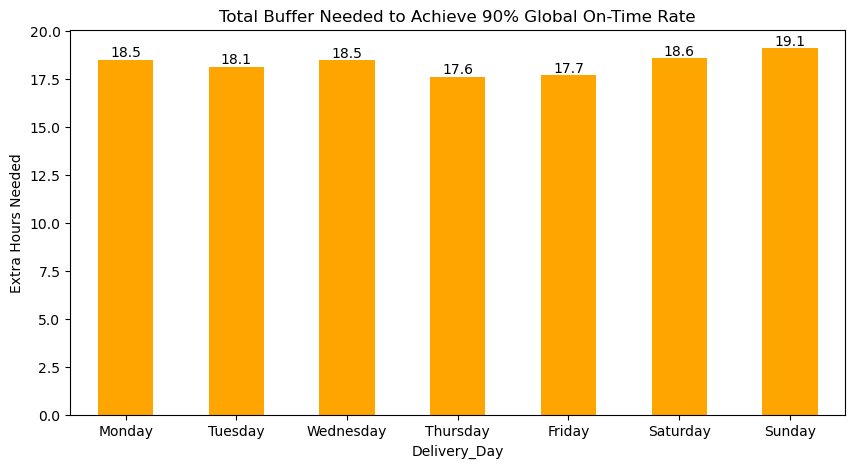

In [7]:
delay_hours = shipment['Difference'].dt.total_seconds() / 3600
delay_needed_by_day = delay_hours.groupby(shipment['Delivery_Day']).quantile(0.9)

days_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
delay_needed_by_day = delay_needed_by_day.reindex(days_order)

plt.figure(figsize=(10, 5))
ax = delay_needed_by_day.plot(kind='bar', color='orange', title='Total Buffer Needed to Achieve 90% Global On-Time Rate')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')

plt.ylabel('Extra Hours Needed')
plt.xticks(rotation=0)
plt.show()


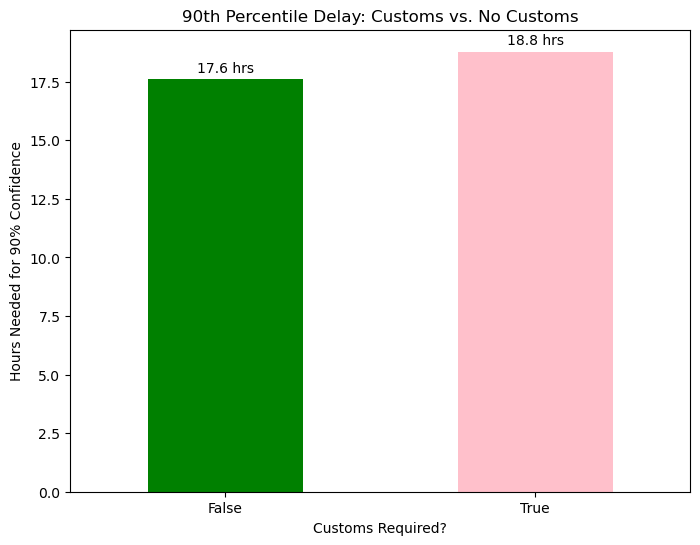

customs_required
False    17.599389
True     18.780056
Name: Difference, dtype: float64


In [10]:
# Validates the adjust by 18-19 hours
# Don't include in paper
customs_validation = shipment.groupby('customs_required')['Difference'].apply(lambda x: x.quantile(0.9).total_seconds() / 3600)

plt.figure(figsize=(8, 6))
ax = customs_validation.plot(kind='bar', color=['green', 'pink'], title='90th Percentile Delay: Customs vs. No Customs')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f hrs', padding=3)

plt.ylabel('Hours Needed for 90% Confidence')
plt.xlabel('Customs Required?')
plt.xticks(rotation=0)
plt.show()

print(customs_validation)


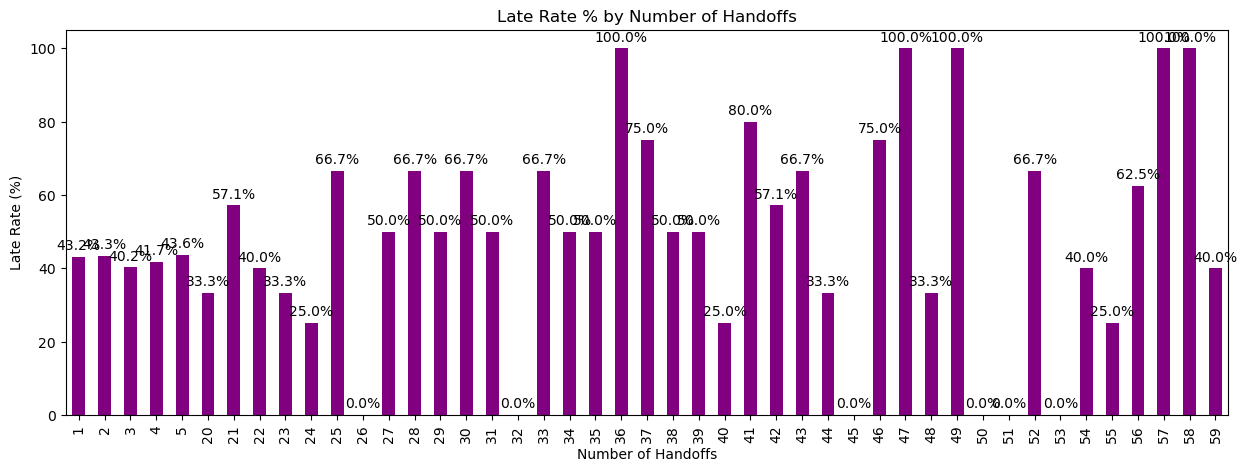

In [37]:
late_by_handoff = shipment.groupby('handoff_count')['Delivered Status (Early or Late)'] \
    .apply(lambda x: (x == 'LATE').mean() * 100)

plt.figure(figsize=(15, 5))
ax = late_by_handoff.plot(kind='bar', color='purple', title='Late Rate % by Number of Handoffs')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.xlabel('Number of Handoffs')
plt.ylabel('Late Rate (%)')
plt.show()


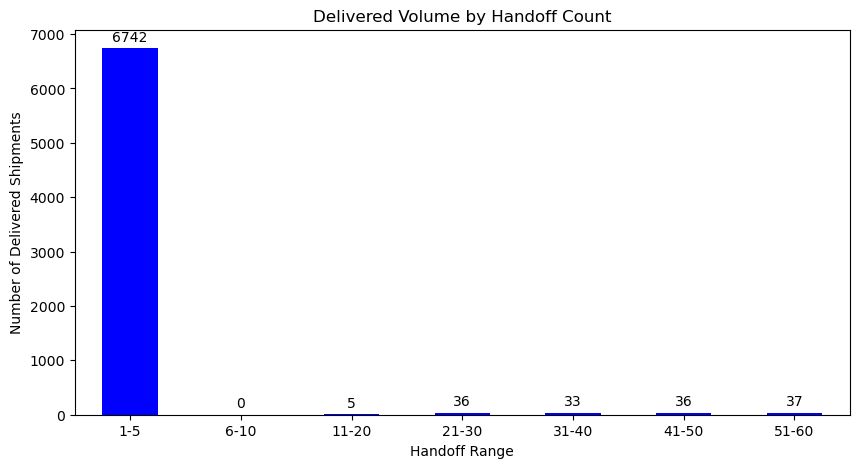

In [58]:
# Handoff count on Delivered
delivered_shipments = shipment[shipment['current_status'] == 'DELIVERED'].copy()

bins = [0, 5, 10, 20, 30, 40, 50, 60]
labels = ['1-5', '6-10', '11-20', '21-30', '31-40', '41-50', '51-60']
delivered_shipments['handoff_bucket'] = pd.cut(delivered_shipments['handoff_count'], bins=bins, labels=labels)
handoff_volume = delivered_shipments['handoff_bucket'].value_counts().reindex(labels)

plt.figure(figsize=(10, 5))
ax = handoff_volume.plot(kind='bar', color='blue', title='Delivered Volume by Handoff Count')
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.xlabel('Handoff Range')
plt.ylabel('Number of Delivered Shipments')
plt.xticks(rotation=0)
plt.show()


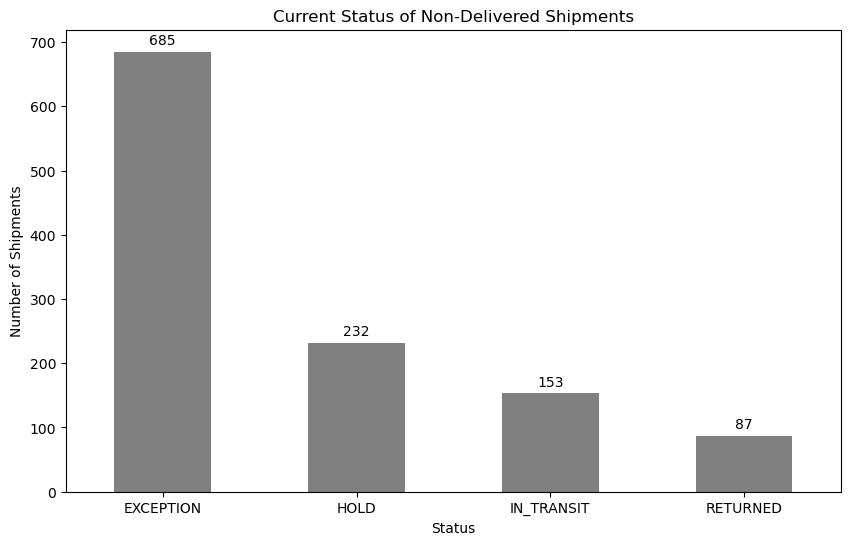

In [54]:
# Graph for everything else, current_status != Delivered
non_delivered_data = shipment[shipment['current_status'] != 'DELIVERED']
status_counts = non_delivered_data['current_status'].value_counts()

plt.figure(figsize=(10, 6))
ax = status_counts.plot(kind='bar', color='gray', title='Current Status of Non-Delivered Shipments')
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.ylabel('Number of Shipments')
plt.xlabel('Status')
plt.xticks(rotation=0) 
plt.show()


In [ ]:
# Don't include the rest in paper!

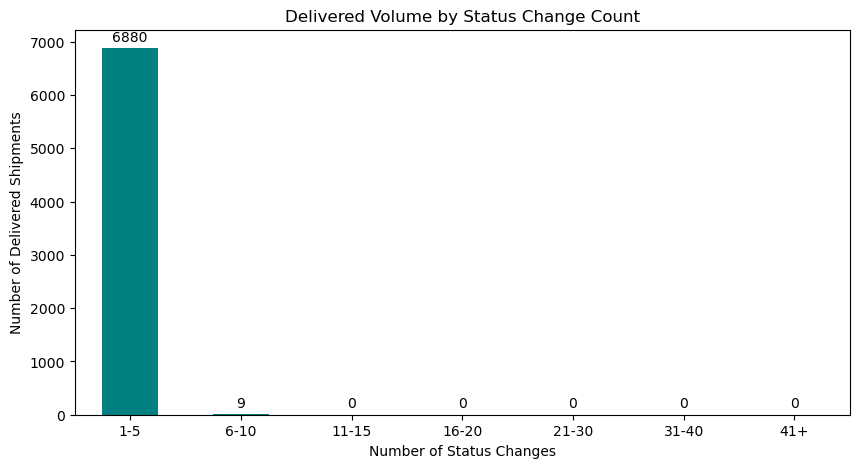

In [60]:
# Don't use in paper
# Wanted to compare to handoff count to see if there are any outliers, there's not
delivered_shipments = shipment[shipment['current_status'] == 'DELIVERED'].copy()

bins = [0, 5, 10, 15, 20, 30, 40, 100]
labels = ['1-5', '6-10', '11-15', '16-20', '21-30', '31-40', '41+']
delivered_shipments['status_bucket'] = pd.cut(delivered_shipments['num_status_changes'], bins=bins, labels=labels)
status_volume = delivered_shipments['status_bucket'].value_counts().reindex(labels)

plt.figure(figsize=(10, 5))
ax = status_volume.plot(kind='bar', color='teal', title='Delivered Volume by Status Change Count')
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.xlabel('Number of Status Changes')
plt.ylabel('Number of Delivered Shipments')
plt.xticks(rotation=0)
plt.show()


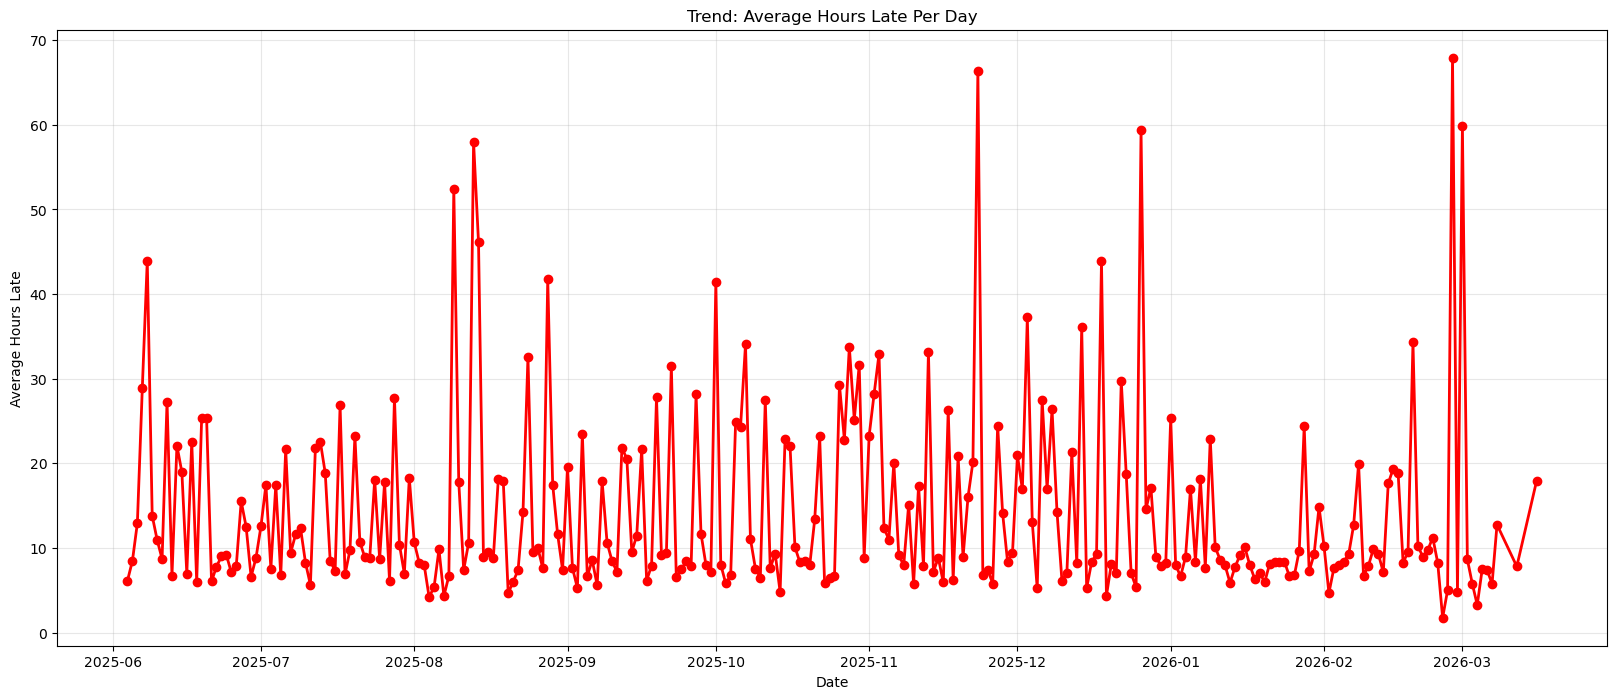

In [13]:
# Interesting, don't include in paper
late_only = shipment[shipment['Delivered Status (Early or Late)'] == 'LATE'].copy()
late_only['Date_Only'] = pd.to_datetime(late_only['Formated_actual_delivery_timestamp']).dt.date
late_only['Hours_Late'] = late_only['Minutes_Late'] / 60
daily_late_trend = late_only.groupby('Date_Only')['Hours_Late'].mean()

plt.figure(figsize=(20, 8))
daily_late_trend.plot(kind='line', color='red', marker='o', linewidth=2)

plt.title('Trend: Average Hours Late Per Day')
plt.ylabel('Average Hours Late')
plt.xlabel('Date')
plt.grid(True, alpha=0.3)
plt.show()


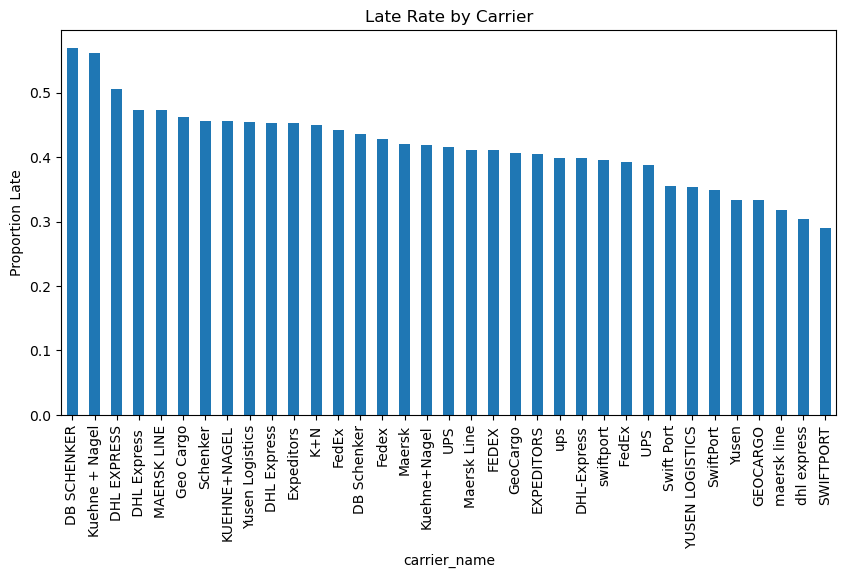

In [4]:
# Interesting, but don't include in paper
late_rate_by_carrier = shipment.groupby('carrier_name')['Delivered Status (Early or Late)'] \
    .apply(lambda x: (x == 'LATE').mean()) \
    .sort_values(ascending=False)

late_rate_by_carrier.plot(kind='bar', figsize=(10,5), title='Late Rate by Carrier')
plt.ylabel('Proportion Late')
plt.show()

In [16]:
# Interesting, but don't include in paper
lane_perf = shipment.groupby(['origin_city', 'destination_city']) \
    .agg(
        total_shipments=('Delivered Status (Early or Late)', 'count'),
        late_rate=('Delivered Status (Early or Late)', lambda x: (x == 'LATE').mean()),
        avg_minutes_late=('Difference', 'mean')
    ) \
    .sort_values(by='late_rate', ascending=False)

lane_perf = lane_perf[lane_perf['total_shipments'] >= 20]
lane_perf['late_shipments'] = lane_perf['total_shipments'] * lane_perf['late_rate']
lane_perf = lane_perf.sort_values(by='late_shipments', ascending=False)

lane_perf['late_shipments'] = shipment.groupby(['origin_city', 'destination_city']) \
    ['Delivered Status (Early or Late)'] \
    .apply(lambda x: (x == 'LATE').sum())

top_problem_lanes = lane_perf[lane_perf['total_shipments'] > 20].head(10)
print(top_problem_lanes)

# About 11 shipments were late on this lane (Leipzig to Cologne)

                              total_shipments  late_rate  \
origin_city destination_city                               
Leipzig     Lille                          22   0.481481   
Cologne     Paris                          25   0.423077   

                                   avg_minutes_late  late_shipments  
origin_city destination_city                                         
Leipzig     Lille            0 days 09:44:49.500000              13  
Cologne     Paris            0 days 11:14:12.080000              11  


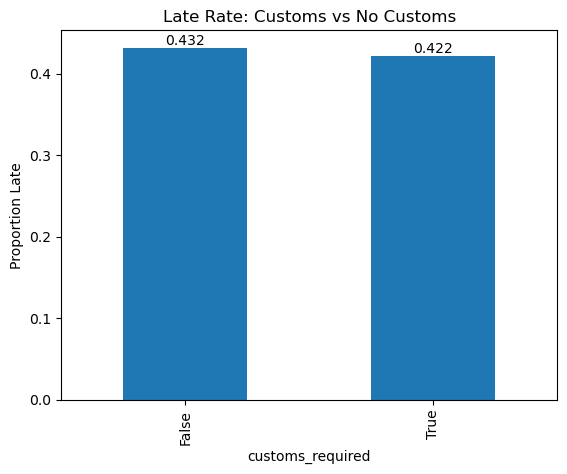

In [27]:
# Very similar, don't include in paper
late_by_customs = shipment.groupby('customs_required')['Delivered Status (Early or Late)'] \
    .apply(lambda x: (x == 'LATE').mean())

ax=late_by_customs.plot(kind='bar', title='Late Rate: Customs vs No Customs')
ax.bar_label(ax.containers[0], fmt='%.3f')
plt.ylabel('Proportion Late')
plt.show()

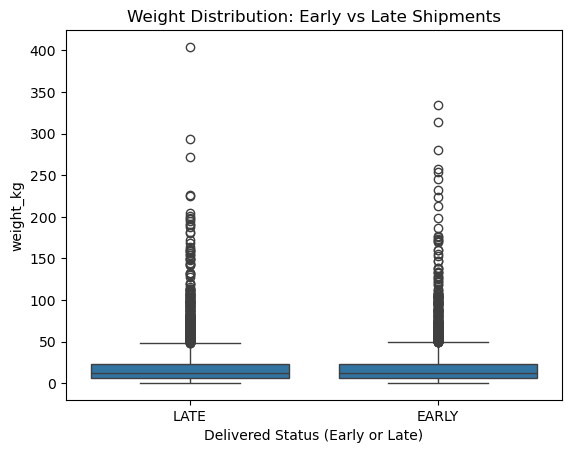

In [15]:
# Ignore - too many outliers, need to split up the weight. Don't use
sns.boxplot(
    data=shipment,
    x='Delivered Status (Early or Late)',
    y='weight_kg'
)
plt.title('Weight Distribution: Early vs Late Shipments')
plt.show()

C:\Users\kcluv\AppData\Local\Temp\ipykernel_22104\599689499.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  late_by_weight = shipment.groupby('weight_bin')['Delivered Status (Early or Late)'] \


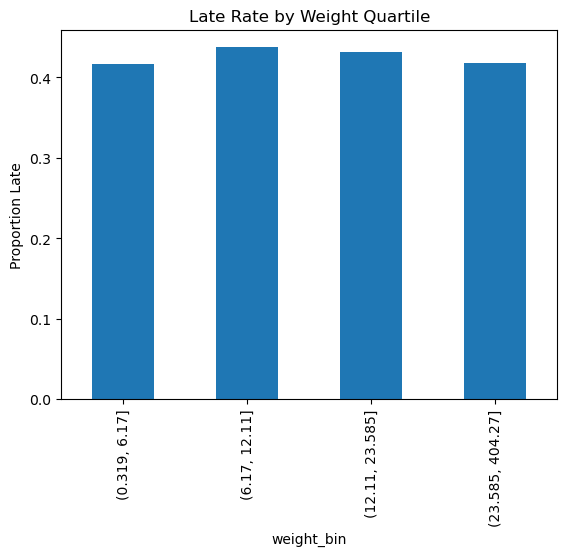

In [16]:
# Very similar, don't include in paper
shipment['weight_bin'] = pd.qcut(shipment['weight_kg'], q=4)

late_by_weight = shipment.groupby('weight_bin')['Delivered Status (Early or Late)'] \
    .apply(lambda x: (x == 'LATE').mean())

late_by_weight.plot(kind='bar', title='Late Rate by Weight Quartile')
plt.ylabel('Proportion Late')
plt.show()

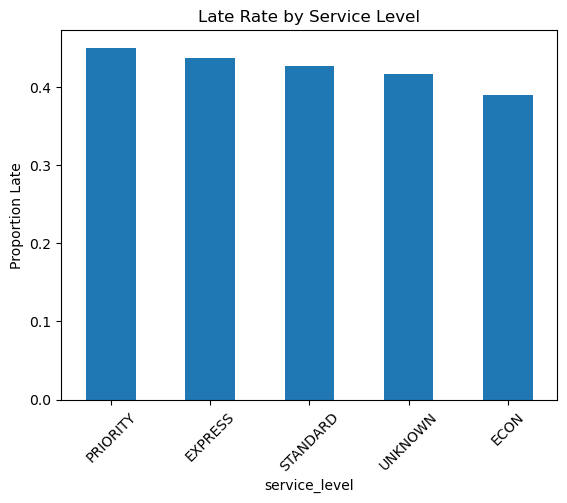

In [19]:
# Very similar, don't include in paper
shipment['service_level'] = (shipment['service_level'].astype(str).str.strip().str.upper())

shipment['service_level'] = shipment['service_level'].replace('', 'UNKNOWN')
shipment['service_level'] = shipment['service_level'].fillna('UNKNOWN')

late_by_service = shipment.groupby('service_level')['Delivered Status (Early or Late)'] \
    .apply(lambda x: (x == 'LATE').mean()) \
    .sort_values(ascending=False)

late_by_service.plot(kind='bar', title='Late Rate by Service Level')
plt.ylabel('Proportion Late')
plt.xticks(rotation=45)
plt.show()